# αSWIFT window lab

Two exponentially decaying complex resonators, their difference window, and a Hann comparison.
This is an **audio-independent analysis prototype**, not a production audio-reactive scene.

Run all cells, then change the sliders. Controls update on release to keep interaction responsive.
The notebook uses NumPy, Matplotlib and ipywidgets; no network access is needed after installation.
If widgets do not appear, open in JupyterLab or a notebook frontend with ipywidgets support.
The saved static plots still show the default configuration.

Optional installation in the notebook's selected Python environment:
```python
%pip install numpy matplotlib ipywidgets
```

## What is being combined?

`x[n]` is audio, `fs` the sample rate, `f0` the center frequency, and `ts`, `tf` the two decay constants in seconds.
Both resonators have the **same center frequency** and the **same unnormalized input gain**:

```text
as = exp(-1 / (fs*ts))
af = exp(-1 / (fs*tf))
r  = exp(i*2*pi*f0/fs)

S[n] = as*r*S[n-1] + x[n]
F[n] = af*r*F[n-1] + x[n]
Y[n] = (S[n] - F[n]) / Z

window[k] = (as^k - af^k) / Z     for age k >= 0
Z = 1/(1-as) - 1/(1-af)
```

Subtract **complex states before magnitude**, not magnitudes, and do not subtract independently normalized EMAs.
The raw windows cancel at age zero, then rise and decay. Swapping `ts` and `tf` gives the same normalized filter.
The normalized difference is exactly a cascade of two normalized one-pole smoothers **plus one sample of delay**.
That identity gives the stable implementation below, including the equal-decay limit.

```text
P[n] = as*r*P[n-1] + (1-as)*x[n]
Q[n] = af*r*Q[n-1] + (1-af)*P[n]
Y[n] = r*Q[n-1]
```

Here `Q[n-1]` means its previous-sample state. At equal decay, the normalized window is
`k*(1-a)^2*a^(k-1)` for `k >= 1`, and zero at `k = 0`. Raw subtraction is identically zero there;
the normalized limit is well-defined. These are steady-state, unit-center-gain comparisons.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as W
from IPython.display import display, clear_output

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True,
                     "grid.alpha": .22, "axes.spines.top": False,
                     "axes.spines.right": False})
COLORS = {"slow": "#3178c6", "fast": "#df8b24", "alpha": "#209779", "hann": "#9656ad"}

def poles(fs, ts, tf):
    # expm1 retains precision for decay constants much longer than one sample.
    ps, pf = -1 / (fs*ts), -1 / (fs*tf)
    return np.exp(ps), np.exp(pf), -np.expm1(ps), -np.expm1(pf)

def responses(d, fs, ts, tf):
    """Exact discrete-time responses at offset d from the resonator frequency."""
    a, b, ca, cb = poles(fs, ts, tf)
    v = np.expm1(-2j*np.pi*np.asarray(d)/fs)
    hs = ca / (ca-a*v)
    hf = cb / (cb-b*v)
    return hs, hf, (1+v)*hs*hf

def dirichlet(d, fs, n):
    """sum(exp(-i*2*pi*d*k/fs), k=0..n-1), including removable singularities."""
    u = (np.asarray(d)/fs + .5) % 1 - .5
    return n*np.exp(-1j*np.pi*(n-1)*u)*np.sinc(n*u)/np.sinc(u)

def hann_response(d, fs, n):
    # Periodic causal Hann: w[k] = .5 - .5*cos(2*pi*k/n), k=0..n-1.
    # Coherent gain is n/2; this is not the symmetric (n-1 denominator) variant.
    return (dirichlet(d, fs, n) - .5*dirichlet(np.asarray(d)-fs/n, fs, n)
            - .5*dirichlet(np.asarray(d)+fs/n, fs, n))/n

def half_width(response, fs):
    lo, hi = 0., fs/2
    for _ in range(55):
        mid = (lo+hi)/2
        if abs(response(mid)) > np.sqrt(.5): lo = mid
        else: hi = mid
    return (lo+hi)/2

def windows(k, fs, ts, tf):
    """Raw individual/difference windows, plus their unit-sum versions."""
    k = np.asarray(k, dtype=float)
    a, b, ca, cb = poles(fs, ts, tf)
    ls, lf = -1/(fs*ts), -1/(fs*tf)
    ws, wf = np.exp(k*ls), np.exp(k*lf)
    # Stable divided difference: (a^k-b^k)/(a-b), multiplied by ca*cb.
    hi, lo = max(ls, lf), min(ls, lf)
    delta = lo-hi
    if delta == 0:
        combined = ca*cb*k*np.exp((k-1)*hi)
    else:
        combined = ca*cb*np.exp((k-1)*hi)*np.expm1(k*delta)/np.expm1(delta)
    return ws, wf, ws-wf, ca*ws, cb*wf, combined

def db(z): return 20*np.log10(np.maximum(np.abs(z), 1e-8))

def stats(fs, ts, tf, n):
    a, b, ca, cb = poles(fs, ts, tf)
    width = half_width(lambda d: responses(d, fs, ts, tf)[2], fs)
    return {"alpha_half_hz": width,
            "hann_half_hz": half_width(lambda d: hann_response(d, fs, n), fs),
            "alpha_age_ms": 1000*(1+a/ca+b/cb)/fs,
            "hann_age_ms": 1000*n/(2*fs)}

## Explore

- **Slow / fast decay:** independent controls; either ordering and equality are valid.
- **Match Hann bandwidth:** chooses the nearest integer Hann length with the same full −3 dB width.
  Switch to **Manual Hann duration** to compare at a chosen duration instead.
- **Raw windows** show exactly what is subtracted. **Unit-area windows** normalize each complete
  window separately for fair comparison; the green curve is not blue minus orange in that panel.
- The frequency plot uses **offset from `f0`**, so its shape is independent of `f0`. Exact discrete-time
  responses are evaluated analytically, not from the displayed/truncated time window.
- The step plot is the normalized cumulative window: the coherent response to an **on-frequency
  complex tone** switched on from silence. Real audio also has a negative-frequency image; at low
  carrier frequency or broad bandwidth it can cause amplitude ripple. The optional complex traces
  show the real parts of impulse responses, not a claim of phase-independent real-tone envelopes.

In [2]:
def draw(ts_ms=50., tf_ms=5., fs=48000, f0=440., hann_mode="Matched −3 dB bandwidth",
         hann_ms=100., span=6., floor=-90, complex_trace=False):
    ts, tf = ts_ms/1000, tf_ms/1000
    bw = half_width(lambda d: responses(d, fs, ts, tf)[2], fs)
    # Long-window Hann half-width ≈ .720291*fs/n; select the best adjacent integer.
    if hann_mode.startswith("Matched"):
        estimate = .7202912900601335*fs/bw
        candidates = sorted({max(4, int(np.floor(estimate))), max(4, int(np.ceil(estimate)))})
        n = min(candidates, key=lambda size: abs(
            half_width(lambda d: hann_response(d, fs, size), fs)-bw))
    else:
        n = max(4, int(round(fs*hann_ms/1000)))
    stop = max(span*max(ts, tf), n/fs)
    # Plot smooth envelopes at up to 6000 ages; the first samples remain visible.
    end = int(np.ceil(stop*fs))
    ages = np.unique(np.r_[np.arange(min(end+1, 128)), np.linspace(0, end, 6000).astype(int)])
    time = ages*1000/fs
    ws, wf, raw, ns, nf, na = windows(ages, fs, ts, tf)
    wh = np.where(ages < n, .5-.5*np.cos(2*np.pi*ages/n), 0.)
    nh = wh/(n/2)
    curves = [("slow", ns, "Slow exponential"), ("fast", nf, "Fast exponential"),
              ("alpha", na, "αSWIFT"), ("hann", nh, "Periodic Hann")]
    fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
    ax = axes[0, 0]
    for key, y, label in [("slow", ws, "Slow: as^k"), ("fast", wf, "Fast: af^k"),
                           ("alpha", raw, "Raw difference: as^k − af^k"),
                           ("hann", wh, "Hann (peak 1)")]:
        ax.plot(time, y, color=COLORS[key], label=label)
    ax.set(title="Raw windows • common input gain", xlabel="Sample age (ms)", ylabel="Weight")
    ax.legend(fontsize=8)
    if ts == tf:
        ax.text(.98, .95, "Raw difference = 0; other panels use its normalized limit",
                ha="right", va="top", transform=ax.transAxes, fontsize=8)
    ax = axes[0, 1]
    for key, y, label in curves:
        ax.plot(time, fs*y, color=COLORS[key], label=label)
    ax.set(title="Unit-area windows • equal coherent gain", xlabel="Sample age (ms)",
           ylabel="Weight density (1/s)")
    ax.legend(fontsize=8)

    # Logarithmic offsets expose leakage tails; stay within one Nyquist interval.
    offsets = np.geomspace(max(.001, min(bw, fs/n)/1000), fs/2, 5000)
    hs, hf, ha = responses(offsets, fs, ts, tf)
    ax = axes[1, 0]
    for key, response, label in [("slow", hs, "Slow exponential"), ("fast", hf, "Fast exponential"),
                                 ("alpha", ha, "αSWIFT"),
                                 ("hann", hann_response(offsets, fs, n), "Periodic Hann")]:
        ax.semilogx(offsets, db(response), color=COLORS[key], label=label)
    ax.axhline(-3.0103, color="gray", lw=.8, ls=":")
    ax.axvline(bw, color=COLORS["alpha"], lw=.8, ls=":")
    ax.set(title="Frequency response • offset from center", xlabel="|f − f0| (Hz)",
           ylabel="Amplitude (dB relative to center)", ylim=(floor, 2))
    ax.legend(fontsize=8)

    # Exact sample-by-sample cumulative sums, not the decimated display window.
    all_ages = np.arange(end+1)
    *_, es, ef, ea = windows(all_ages, fs, ts, tf)
    eh = np.where(all_ages < n, .5-.5*np.cos(2*np.pi*all_ages/n), 0)/(n/2)
    ax = axes[1, 1]
    times = {}
    for key, y, label in [("slow", es, "Slow exponential"), ("fast", ef, "Fast exponential"),
                          ("alpha", ea, "αSWIFT"), ("hann", eh, "Periodic Hann")]:
        step = np.cumsum(y)
        ax.plot(time, step[ages], color=COLORS[key], label=label)
        times[key] = [np.searchsorted(step, p)/fs*1000 if step[-1] >= p else np.nan for p in [.5, .9]]
    ax.axhline(.5, color="gray", lw=.8, ls=":")
    ax.axhline(.9, color="gray", lw=.8, ls=":")
    ax.set(title="Coherent amplitude buildup • switched-on complex tone", xlabel="Time after onset (ms)",
           ylabel="Fraction of final amplitude", ylim=(0, 1.04))
    ax.legend(fontsize=8)
    plt.show()
    plt.close(fig)

    s = stats(fs, ts, tf, n)
    print(f"fs = {fs:,} Hz | f0 = {f0:g} Hz | Hann = {n:,} samples ({1000*n/fs:.3f} ms)")
    print(f"Full −3 dB width: αSWIFT {2*s['alpha_half_hz']:.3f} Hz | Hann {2*s['hann_half_hz']:.3f} Hz")
    print(f"Mean sample age: αSWIFT {s['alpha_age_ms']:.3f} ms | Hann {s['hann_age_ms']:.3f} ms")
    print("                     50% buildup     90% buildup")
    for key, label in [("slow", "Slow exponential"), ("fast", "Fast exponential"),
                        ("alpha", "αSWIFT"), ("hann", "Hann")]:
        vals = times[key]
        print(f"{label:18s} {vals[0]:10.3f} ms  {vals[1]:10.3f} ms")
    if ts < tf:
        print("Note: named ‘fast’ is slower than named ‘slow’; normalized αSWIFT is unchanged by swapping them.")
    if f0 >= fs/2:
        print("Center frequency must be below Nyquist to represent a distinct positive-frequency audio band.")
    image = abs(responses(2*f0, fs, ts, tf)[2])
    print(f"Real-tone negative-frequency image through αSWIFT: {float(db(image)):.1f} dB relative to wanted tone.")
    print("Infinite tails are cropped only in time plots; frequency curves and mean ages use complete windows.")

    if complex_trace:
        # Short trace at native sample spacing; includes normalized complex combination.
        k = np.arange(min(end+1, max(16, int(fs*min(stop, 8/max(f0, 1))))))
        _, _, _, us, uf, ua = windows(k, fs, ts, tf)
        carrier = np.exp(2j*np.pi*f0*k/fs)
        fig, ax = plt.subplots(figsize=(13, 3), constrained_layout=True)
        for key, y, label in [("slow", us, "Slow"), ("fast", uf, "Fast"), ("alpha", ua, "Combined")]:
            ax.plot(k*1000/fs, fs*np.real(y*carrier), color=COLORS[key], label=label)
        ax.set(title="Real parts of the complex impulse responses • first eight carrier cycles",
               xlabel="Sample age (ms)", ylabel="Normalized real weight × fs")
        ax.legend()
        plt.show()
        plt.close(fig)

controls = {
    "ts_ms": W.FloatLogSlider(value=50, base=10, min=-1, max=np.log10(500), step=.02,
                              description="Slow decay ms", continuous_update=False, readout_format=".2f"),
    "tf_ms": W.FloatLogSlider(value=5, base=10, min=-1, max=np.log10(500), step=.02,
                              description="Fast decay ms", continuous_update=False, readout_format=".2f"),
    "fs": W.Dropdown(options=[8000, 44100, 48000, 96000], value=48000, description="Sample rate"),
    "f0": W.FloatLogSlider(value=440, base=10, min=np.log10(20), max=np.log10(3500), step=.02,
                           description="Center Hz", continuous_update=False, readout_format=".1f"),
    "hann_mode": W.Dropdown(options=["Matched −3 dB bandwidth", "Manual Hann duration"],
                            description="Hann mode", layout=W.Layout(width="390px")),
    "hann_ms": W.FloatLogSlider(value=100, base=10, min=0, max=np.log10(3000), step=.02,
                                description="Hann ms", continuous_update=False, readout_format=".2f"),
    "span": W.FloatSlider(value=6, min=2, max=12, step=.5, description="Tail constants", continuous_update=False),
    "floor": W.IntSlider(value=-90, min=-140, max=-30, step=10, description="dB floor", continuous_update=False),
    "complex_trace": W.Checkbox(value=False, description="Show complex resonator traces", indent=False),
}
for widget in controls.values():
    widget.style = {"description_width": "115px"}
    if not isinstance(widget, (W.Dropdown, W.Checkbox)):
        widget.layout.width = "390px"
def update_hann_control(change=None):
    controls["hann_ms"].disabled = controls["hann_mode"].value.startswith("Matched")
controls["hann_mode"].observe(update_hann_control, names="value")
update_hann_control()
panel = W.VBox([W.HBox([controls["ts_ms"], controls["tf_ms"]]),
                W.HBox([controls["hann_mode"], controls["hann_ms"]]),
                W.HBox([controls["fs"], controls["f0"]]),
                W.HBox([controls["span"], controls["floor"]]), controls["complex_trace"]])
output = W.interactive_output(draw, controls)
display(panel, output)

Output()

## Edit the mathematics

`responses`, `windows`, and `hann_response` above are the functions to modify. The controls merely call
`draw`. For example, this creates an additional static plot without changing slider values:

```python
draw(ts_ms=20, tf_ms=2, hann_mode="Manual Hann duration", hann_ms=40, complex_trace=True)
```

The two decay constants shape the same causal window; they are **not independent attack and release
controls** of a nonlinear envelope follower. Faster initial taper generally admits more off-frequency
energy. Compare equal bandwidth before attributing improvements to window shape.

References: [Cornell SWIFT/αSWIFT implementation](https://people.ece.cornell.edu/land/courses/ece4760/RP2350/SWIFT/index_swift.html),
[lock-in filter bandwidth and settling](https://blogs.zhinst.com/en/resources/principles-of-lock-in-detection/).

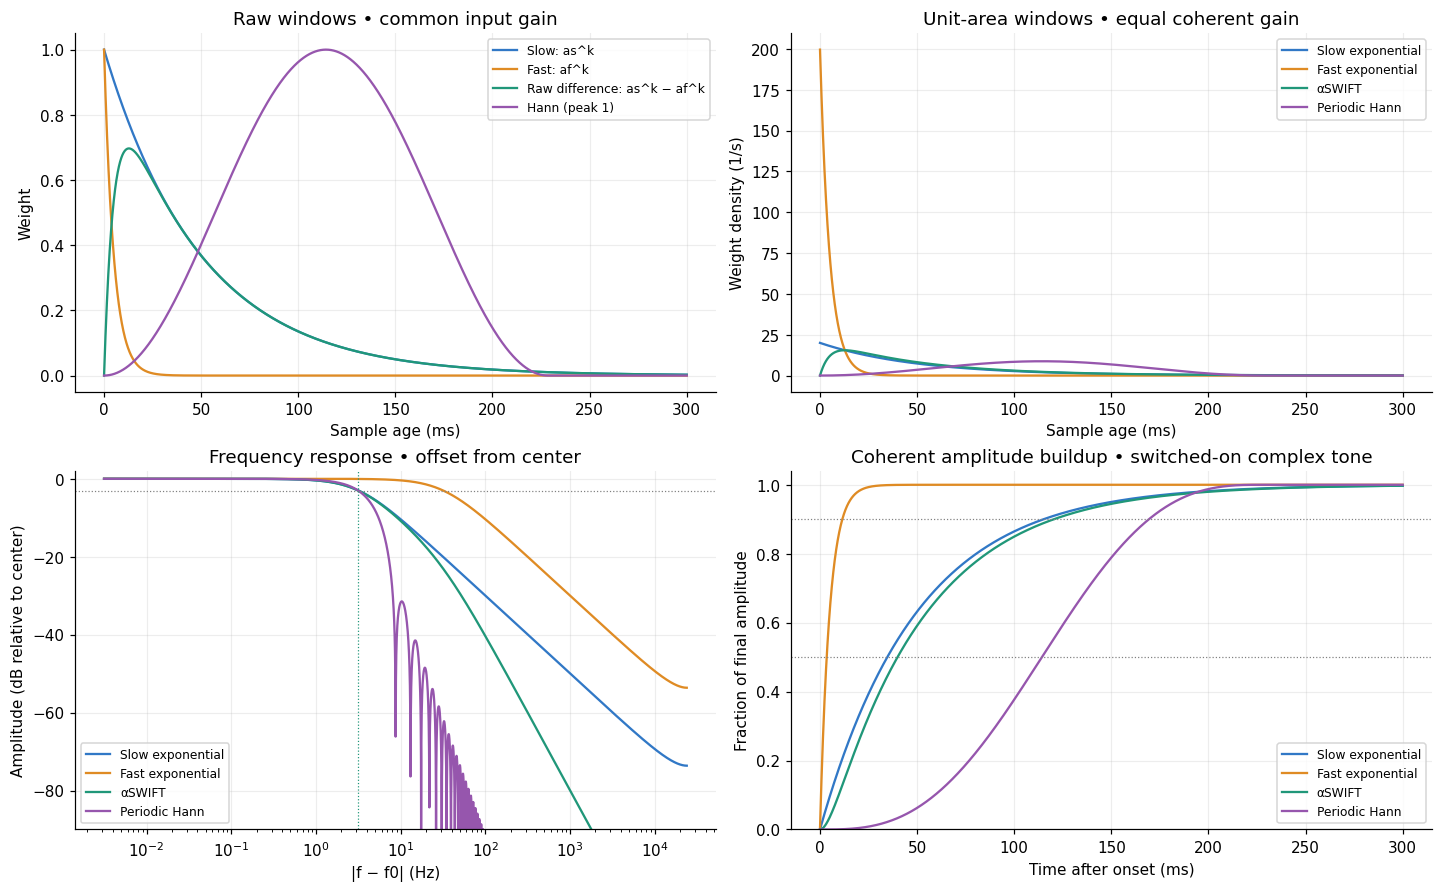

fs = 48,000 Hz | f0 = 440 Hz | Hann = 10,969 samples (228.521 ms)
Full −3 dB width: αSWIFT 6.304 Hz | Hann 6.304 Hz
Mean sample age: αSWIFT 55.000 ms | Hann 114.260 ms
                     50% buildup     90% buildup
Slow exponential       34.646 ms     115.125 ms
Fast exponential        3.458 ms      11.500 ms
αSWIFT                 39.917 ms     120.396 ms
Hann                  114.271 ms     169.354 ms
Real-tone negative-frequency image through αSWIFT: -77.7 dB relative to wanted tone.
Infinite tails are cropped only in time plots; frequency curves and mean ages use complete windows.


In [3]:
# A static default snapshot is saved as well as the live widget output.
# This remains readable in notebook viewers without widget support.
draw()

## Numerical checks

Check unit center gain, causal recurrence versus analytic window, the equal-decay limit,
swap symmetry, and periodic Hann against a direct window sum. The frequency curves above
use exact discrete-time responses; these checks are independent of the plot sampling.

In [4]:
def verify():
    fs = 48000
    for ts, tf in [(.05, .005), (.005, .05), (.01, .01), (.01, .010000000001)]:
        a, b, ca, cb = poles(fs, ts, tf)
        k = np.arange(int(np.ceil(35*max(ts, tf)*fs)))
        w = windows(k, fs, ts, tf)[-1]
        assert abs(w.sum()-1) < 1e-11
        assert w[0] == 0 and np.all(w >= 0)
        np.testing.assert_allclose(w, windows(k, fs, tf, ts)[-1], rtol=1e-10, atol=1e-14)
        assert abs(responses(0, fs, ts, tf)[2]-1) < 1e-14
        # Independent cascade recurrence at baseband, followed by a one-sample delay.
        p = q = 0.
        impulse = np.empty(len(k))
        for j in range(len(k)):
            impulse[j] = q
            p = a*p + ca*(j == 0)
            q = b*q + cb*p
        np.testing.assert_allclose(w, impulse, rtol=1e-9, atol=1e-14)
        for d in [0, 3.7, 500.3]:
            direct = np.sum(w*np.exp(-2j*np.pi*d*k/fs))
            np.testing.assert_allclose(direct, responses(d, fs, ts, tf)[2], atol=1e-11)
    for n in [4, 101, 4800]:
        k = np.arange(n)
        w = (.5-.5*np.cos(2*np.pi*k/n))/(n/2)
        for d in [0, fs/n, -fs/n, 47.3, fs/2]:
            np.testing.assert_allclose(hann_response(d, fs, n),
                np.sum(w*np.exp(-2j*np.pi*d*k/fs)), atol=2e-12)
    print("Passed: center gain, normalization, recurrence, equal/near-equal decay, swap symmetry, and Hann response.")

verify()

Passed: center gain, normalization, recurrence, equal/near-equal decay, swap symmetry, and Hann response.


## Cycles, neighboring notes, and response time

These controls are independent of the original millisecond lab above. A decay of **3 cycles** means
`tau = 3/f0` seconds, the time for that individual exponential to fall to `1/e`, not a finite window.
The default pair is slow = 5 cycles, fast = 3 cycles. Both contribute to the combined delay.

Compare Hann at equal **−3 dB bandwidth**, equal **nearest-note rejection**, the **current production
length**, or a manual duration. Production length is `round(round(Q)*fs/f0)` with
`Q = 1/(2**(1/bins_per_octave)-1)`; this describes the Hann length in the current scalar/SIMD DFT.
Equal nearest-note rejection matches at the closer of the two adjacent log-frequency bins,
using the shortest Hann length on its main lobe. It does not match leakage at other offsets.
Neither matching rule guarantees separation of unequal simultaneous tones.

The single fast exponential is a candidate fast observation path. All filters have unit coherent
center gain. Step and release curves use complex on-frequency tones; the real-audio experiment
below includes the negative-frequency image, phase, overlap and detuning.

In [5]:
def choose_hann(fs, f0, ts, tf, bins, mode, manual_cycles):
    gap = f0*(1-2**(-1/bins))  # closer, lower neighboring bin
    if mode == "Production length":
        return max(4, int(round(round(1/(2**(1/bins)-1))*fs/f0)))
    if mode == "Manual cycles":
        return max(4, int(round(manual_cycles*fs/f0)))
    if mode == "Matched bandwidth":
        bw = half_width(lambda d: responses(d, fs, ts, tf)[2], fs)
        guess = .7202912900601335*fs/bw
        candidates = {max(4, int(np.floor(guess))), max(4, int(np.ceil(guess)))}
        return min(candidates, key=lambda n: abs(half_width(lambda d: hann_response(d, fs, n), fs)-bw))
    target = abs(responses(gap, fs, ts, tf)[2])
    lo, hi = 4, max(5, int(np.ceil(2*fs/gap)))
    while hi-lo > 1:
        mid = (lo+hi)//2
        if abs(hann_response(gap, fs, mid)) > target: lo = mid
        else: hi = mid
    return min((lo, hi), key=lambda n: abs(abs(hann_response(gap, fs, n))-target))

def filter_kernels(fs, f0, slow, fast, n, count):
    k = np.arange(count)
    ts, tf = slow/f0, fast/f0
    single = windows(k, fs, ts, tf)[4]
    alpha = windows(k, fs, ts, tf)[5]
    hann = np.where(k < n, .5-.5*np.cos(2*np.pi*k/n), 0)/(n/2)
    return [single, alpha, hann]

def crossing(step, fraction, fs):
    hits = np.flatnonzero(step >= fraction)
    return hits[0]/fs if len(hits) else np.nan

def note_lab(f0=55., slow=5., fast=3., bins=12, mode="Matched neighboring note",
             manual_cycles=17., fs=48000):
    ts, tf = slow/f0, fast/f0
    n = choose_hann(fs, f0, ts, tf, bins, mode, manual_cycles)
    count = int(np.ceil(max(12*max(ts, tf), n/fs)*fs))+1
    k = np.arange(count)
    kernels = filter_kernels(fs, f0, slow, fast, n, count)
    names = ["Fast exponential", "Two-pole cascade", "Periodic Hann"]
    colors = [COLORS["fast"], COLORS["alpha"], COLORS["hann"]]
    sample = np.unique(np.linspace(0, count-1, min(count, 6000)).astype(int))
    fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
    semitones = np.linspace(-6, 6, 2401)
    offsets = f0*(2**(semitones/12)-1)
    _, hf, ha = responses(offsets, fs, ts, tf)
    hs = [hf, ha, hann_response(offsets, fs, n)]
    print(f"Center {f0:g} Hz | slow {slow:g} cycles ({ts*1000:.2f} ms) | "
          f"fast {fast:g} cycles ({tf*1000:.2f} ms)")
    print(f"Hann: {n} samples = {n*f0/fs:.3f} cycles = {n/fs*1000:.2f} ms | {mode}")
    print("                           mean age    t10       t50       t90     release to 10%")
    for label, color, w, h in zip(names, colors, kernels, hs):
        step = np.cumsum(w)
        qs = [1000*crossing(step, p, fs) for p in [.1, .5, .9]]
        age = (np.sum(k*w)/fs if label == "Periodic Hann" else
               (poles(fs, ts, tf)[1]/poles(fs, ts, tf)[3]/fs if label == "Fast exponential"
                else (1+poles(fs, ts, tf)[0]/poles(fs, ts, tf)[2]
                      +poles(fs, ts, tf)[1]/poles(fs, ts, tf)[3])/fs))
        print(f"{label:24s} {age*1000:8.2f} {qs[0]:9.2f} {qs[1]:9.2f} {qs[2]:9.2f} {qs[2]:14.2f} ms")
        axes[0, 0].plot(k[sample]/fs*1000, fs*w[sample], color=color, label=label)
        axes[0, 1].plot(semitones, db(h), color=color, label=label)
        axes[1, 0].plot(k[sample]/fs*1000, step[sample], color=color, label=label)
        # Switched off immediately after n=0; first release output is 1-w[0].
        axes[1, 1].plot(k[sample]/fs*1000, np.maximum(0, 1-step[sample]), color=color, label=label)
    axes[0, 0].set(title="Age density · unit area", xlabel="Sample age (ms)", ylabel="Weight per second")
    axes[0, 1].set(title="Leakage at musical offsets", xlabel="Semitones from center", ylabel="Amplitude (dB)", ylim=(-80, 2))
    for sign in [-1, 1]: axes[0, 1].axvline(sign*12/bins, color="gray", ls=":", lw=1)
    axes[1, 0].set(title="Coherent attack", xlabel="Time from onset (ms)", ylabel="Amplitude / final", ylim=(0, 1.02))
    axes[1, 1].set(title="Coherent release from steady state", xlabel="Time from offset (ms)", ylabel="Amplitude / previous", ylim=(0, 1.02))
    for ax in axes.flat: ax.legend(fontsize=8)
    plt.show(); plt.close(fig)
    print("Leakage relative to the same filter's coherent center response:")
    print("offset (bins)      Fast dB     Cascade dB      Hann dB")
    for j in [-2, -1, -.5, .5, 1, 2]:
        d = f0*(2**(j/bins)-1)
        _, f, a = responses(d, fs, ts, tf)
        print(f"{j:9.1f} {float(db(f)):16.2f} {float(db(a)):14.2f} {float(db(hann_response(d, fs, n))):12.2f}")
    a, b, ca, cb = poles(fs, ts, tf)
    # Squared norms of the infinite unit-area windows; stable also when a == b.
    norms = [cb/(1+b), ca*cb*(1+a*b)/((1+a)*(1+b)*(-np.expm1(-1/(fs*ts)-1/(fs*tf)))), 1.5/n]
    print("White-noise gains (unit coherent center gain; ENBW is two-sided):")
    for label, norm in zip(names, norms):
        print(f"{label:24s} ENBW {fs*norm:8.3f} Hz | RMS of 2*abs(z) / input noise RMS = {2*np.sqrt(norm):.5f}")
    print("These noise RMS gains concern the second moment, not the mean noise magnitude.")
    print("A tone 20 dB louder contributes its leakage dB + 20 dB relative to a unit center tone.")
    print("Release to 10% equals attack to 90% here; these are not independent controls.")

note_controls = {
    "f0": W.FloatLogSlider(value=55, min=np.log10(30), max=np.log10(1500), description="Center Hz", continuous_update=False),
    "slow": W.FloatSlider(value=5, min=.25, max=16, step=.25, description="Slow cycles", continuous_update=False),
    "fast": W.FloatSlider(value=3, min=.25, max=16, step=.25, description="Fast cycles", continuous_update=False),
    "bins": W.Dropdown(options=[6, 12, 24, 48], value=12, description="Bins/octave"),
    "mode": W.Dropdown(options=["Matched neighboring note", "Matched bandwidth", "Production length", "Manual cycles"],
                       description="Hann match", layout=W.Layout(width="440px")),
    "manual_cycles": W.FloatSlider(value=17, min=1, max=100, step=1, description="Hann cycles", continuous_update=False),
}
note_output = W.interactive_output(note_lab, note_controls)
display(W.VBox([W.HBox([note_controls["f0"], note_controls["bins"]]),
                W.HBox([note_controls["slow"], note_controls["fast"]]),
                W.HBox([note_controls["mode"], note_controls["manual_cycles"]])]), note_output)

Output()

### Families of compromises

The sweep below compares **median coherent buildup time** with rejection at the closer adjacent note.
Each curve varies the slow decay from 0.5 to 24 carrier cycles. Colors select the fast/slow ratio.
Hann varies from 2 cycles to its first null at that neighbor; later sidelobe coincidences are excluded.
This is a design-family comparison, not a proof of an optimal window or a noisy two-tone resolution limit.
Sweep buildup uses continuous-time exponential formulas; the interactive lab above uses exact discrete samples.
The horizontal axis is in carrier cycles: divide by frequency to obtain seconds.

In [6]:
def continuous_median(slow, fast):
    b, a = max(slow, fast), min(slow, fast)
    def cdf(t):
        if abs(b-a) < 1e-8*b: return 1-np.exp(-t/b)*(1+t/b)
        return 1-np.exp(-t/b)*(1-a*np.expm1(t*(1/b-1/a))/(b-a))
    lo, hi = 0., 20*(a+b)
    for _ in range(55):
        mid = (lo+hi)/2
        if cdf(mid) < .5: lo = mid
        else: hi = mid
    return (lo+hi)/2

def tradeoff_plot(bins=12):
    gap = 1-2**(-1/bins)
    slow = np.geomspace(.5, 24, 120)
    fig, ax = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
    for ratio in [.05, .2, .6, 1.]:
        rejection = 10*np.log10((1+(2*np.pi*gap*slow)**2)*(1+(2*np.pi*gap*ratio*slow)**2))
        median = [continuous_median(s, ratio*s) for s in slow]
        ax.plot(median, rejection, label=f"Cascade: fast/slow = {ratio:g}")
    # Normalized continuous Hann has median at half its support.
    lengths = np.linspace(2, 1.99/gap, 500)
    v = gap*lengths
    h = np.sinc(v)+.5*(np.sinc(v-1)+np.sinc(v+1))
    ax.plot(lengths/2, -db(h), color=COLORS["hann"], ls="--", label="Hann · before first null")
    d = gap
    rejection = 10*np.log10((1+(2*np.pi*d*5)**2)*(1+(2*np.pi*d*3)**2))
    ax.scatter([continuous_median(5, 3)], [rejection], color="black", zorder=5, label="5 / 3 cycles")
    ax.set(xlabel="Time to 50% coherent amplitude (carrier cycles)", ylabel="Nearest-note rejection (dB)",
           title=f"Response versus neighboring-note rejection · {bins} bins/octave", ylim=(0, 55))
    ax.legend(fontsize=9); plt.show(); plt.close(fig)

tradeoff_control = W.Dropdown(options=[6, 12, 24, 48], value=12, description="Bins/octave")
tradeoff_output = W.interactive_output(tradeoff_plot, {"bins": tradeoff_control})
display(tradeoff_control, tradeoff_output)

Dropdown(description='Bins/octave', index=1, options=(6, 12, 24, 48), value=12)

Output()

## What the STBR fit actually observes

The current [`Splitter.cs`](../AEther/Splitter.cs) fits **linear magnitudes** `A = 2*abs(z)`, with
optional time slopes for S and log-frequency slopes for T. Its local sufficient statistics include:

- Per-bin temporal means, second central moments, and optional time cross-moments.
- Current frequency-neighborhood means `q` and tilts `d`.
- Temporal means and second central moments of `q` and `d`.

The second moments of neighborhood means carry cross-bin information: per-bin variances alone cannot
recover them. The Gaussian fit's residual RMS describes unexplained time/frequency interaction over
the patch. It is distinct from the signed current-cell residual and need not represent physical noise.

The following is a **direct reference projection**, rather than a port of the optimized rolling kernel.
It fits a centered two-octave patch at the selected bin (also a full-domain fit over the displayed patch).
S is plotted as the RMS of its current signed frequency field; T is the current frequency mean minus B;
R is the patch residual RMS. This matches the meanings of the production global summary.
Slopes default to the current code's settings: S time slope off, T frequency slope on.

Two time-weighting choices are available: the production finite rectangle, or an experimental common
exponential measure. The exponential has the same steady-state **mean sample age** as the rectangle,
and this choice also matches the effective sample count for independent, equally noisy observations.
Their age variances and finite support differ; actual overlapping DFT rows are correlated.
Both normalize only over available rows during startup.
Exponential weighting changes the estimator; the reference calculation retains history to show its target.
Its separable weighted moments could be updated recursively without an outgoing-row ring.

In [7]:
def project_patch(patch, time_slope=False, frequency_slope=True, weights=None):
    """Direct weighted directional projection. Rows=time, columns=log frequency."""
    a = np.asarray(patch, dtype=float)
    nt, nf = a.shape
    weights = np.ones(nt) if weights is None else np.asarray(weights, dtype=float)
    weights = weights/weights.sum()
    u = np.arange(nt, dtype=float)
    u = (u-np.dot(weights, u))/max(1, nt-1)
    x = np.linspace(-1, 1, nf) if nf > 1 else np.zeros(1)
    vu, vx = np.dot(weights, u*u), np.mean(x*x)
    m = weights@a
    q = a.mean(axis=1)
    b = m.mean()
    at = (weights*u)@a/vu if time_slope and vu > 0 else np.zeros(nf)
    d = a@x/(nf*vx) if frequency_slope and vx > 0 else np.zeros(nt)
    abar, dbar = at.mean(), np.dot(weights, d)
    c = np.mean(at*x)/vx if time_slope and frequency_slope and vx > 0 else 0.
    sf = m[None, :]-b+(at[None, :]-abar-.5*c*x[None, :])*u[:, None]
    tf = q[:, None]-b+(d[:, None]-dbar-.5*c*u[:, None])*x[None, :]
    residual = a-b-sf-tf
    rms = np.sqrt(np.sum(weights[:, None]*residual**2)/nf)
    return dict(B=b, T=q[-1]-b, S=np.sqrt(np.mean(sf[-1]**2)), R=rms,
                current_residual=residual[-1, nf//2], prediction=b+sf+tf, residual=residual)

def stbr_trace(magnitudes, rate, duration=.2, time_slope=False, frequency_slope=True,
               weighting="Finite rectangle"):
    length = max(3, int(round(duration*rate)) | 1)
    # r/(1-r) = (length-1)/2 samples: equal steady-state mean age.
    r = (length-1)/(length+1)
    result = {key: np.zeros(len(magnitudes)) for key in ["B", "T", "S", "R", "current_residual"]}
    for j in range(len(magnitudes)):
        start = max(0, j-length+1) if weighting == "Finite rectangle" else 0
        patch = magnitudes[start:j+1]
        weights = None if weighting == "Finite rectangle" else r**np.arange(len(patch)-1, -1, -1)
        fit = project_patch(patch, time_slope, frequency_slope, weights)
        for key in result: result[key][j] = fit[key]
    return result

def fft_filter_bank(audio, frequencies, fs, slow, fast, hann_mode, bins=12):
    """Offline exact causal convolution; no lookahead. No performance claim."""
    count = len(audio)
    ns = [choose_hann(fs, f, slow/f, fast/f, bins, hann_mode, 17) for f in frequencies]
    fft_size = 1 << (2*count-1).bit_length()
    spectrum = np.fft.fft(audio, fft_size)
    frames = np.arange(0, count, fs//200)  # 200 observations/second
    output = [np.empty((len(frames), len(frequencies))) for _ in range(3)]
    ages = np.arange(count)
    for j, (f, n) in enumerate(zip(frequencies, ns)):
        carrier = np.exp(2j*np.pi*f*ages/fs)
        for p, window in enumerate(filter_kernels(fs, f, slow, fast, n, count)):
            z = np.fft.ifft(spectrum*np.fft.fft(window*carrier, fft_size))[:count]
            output[p][:, j] = 2*np.abs(z[frames])
    return frames/fs, output

def audio_experiment(f0=55., slow=5., fast=3., scenario="Tone plus noise burst", neighbor_db=0.,
                     phase=0., cents=0., hann_mode="Matched neighboring note", fit_ms=200.,
                     time_slope=False, frequency_slope=True, weighting="Finite rectangle"):
    fs, stop, rate = 8000, 2.5, 200
    t = np.arange(int(fs*stop))/fs
    frequencies = f0*2**(np.arange(-12, 13)/12)
    rng = np.random.default_rng(417)
    on, off = .3, 1.25
    gate = ((t >= on) & (t < off)).astype(float)
    f = f0*2**(cents/1200)
    base = np.cos(2*np.pi*f*t+phase)*gate
    boundaries = [on, off]
    if scenario == "Tone plus noise burst":
        burst = ((t >= .65) & (t < .73)).astype(float)
        audio = .3*base+.3*rng.standard_normal(len(t))*burst
        boundaries += [.65, .73]
    elif scenario == "Neighbor overlaps":
        other = ((t >= .65) & (t < 1.6)).astype(float)
        audio = .3*(base+10**(neighbor_db/20)*np.cos(2*np.pi*f*2**(1/12)*t+phase+1.1)*other)
        boundaries += [.65, 1.6]
    elif scenario == "Neighbor replaces tone":
        switch = .8
        audio = .3*np.where(t < switch, np.cos(2*np.pi*f*t+phase),
                            10**(neighbor_db/20)*np.cos(2*np.pi*f*2**(1/12)*t+phase+1.1))*gate
        boundaries += [switch]
    elif scenario == "Synchronous bin tones":
        # Deterministic phases and simultaneous gates; all frequencies start together.
        ph = rng.uniform(-np.pi, np.pi, len(frequencies))
        audio = .3*np.cos(2*np.pi*t[:, None]*frequencies[None, :]+ph).sum(axis=1)/np.sqrt(len(frequencies))*gate
    else:
        audio = .3*rng.standard_normal(len(t))*gate
    times, banks = fft_filter_bank(audio, frequencies, fs, slow, fast, hann_mode)
    fits = [stbr_trace(a, rate, fit_ms/1000, time_slope, frequency_slope, weighting) for a in banks]
    names = ["Fast exponential", "Two-pole cascade", "Periodic Hann"]
    peak = max(np.max(a) for a in banks)
    fig, axes = plt.subplots(3, 3, figsize=(15, 9), constrained_layout=True, sharex=True)
    for col, (name, a, fit) in enumerate(zip(names, banks, fits)):
        im = axes[0, col].pcolormesh(times, np.arange(-12, 13), db(a/max(peak, 1e-15)).T,
                                    shading="auto", vmin=-60, vmax=0, cmap="magma")
        axes[0, col].set(title=name, ylabel="Semitones from center")
        axes[1, col].plot(times, fit["T"], label="T · signed current mean − B", color=COLORS["fast"])
        axes[1, col].plot(times, fit["B"], label="B · patch mean", color="gray")
        axes[1, col].axhline(0, color="gray", lw=.7)
        axes[1, col].set(ylabel="Linear amplitude", title="Temporal effect and background")
        axes[2, col].plot(times, fit["S"], label="S · current field RMS", color=COLORS["slow"])
        axes[2, col].plot(times, fit["R"], label="R · patch residual RMS", color=COLORS["alpha"])
        axes[2, col].set(xlabel="Time (s)", ylabel="Linear amplitude", title="Structure and interaction")
        for row in [1, 2]: axes[row, col].legend(fontsize=8)
        for row in range(3):
            for edge in boundaries: axes[row, col].axvline(edge, color="gray", lw=.7, ls=":")
    # Share amplitude limits across paths, retaining the negative T range.
    for row in [1, 2]:
        low = min(ax.get_ylim()[0] for ax in axes[row]); high = max(ax.get_ylim()[1] for ax in axes[row])
        for ax in axes[row]: ax.set_ylim(low, high)
    fig.colorbar(im, ax=axes[0, :], label="Magnitude (dB / common peak)", shrink=.75)
    fig.suptitle(f"{scenario} · real audio · center {f0:g} Hz · {weighting} · fit {fit_ms:g} ms")
    plt.show(); plt.close(fig)
    fig, ax = plt.subplots(figsize=(13, 1.6), constrained_layout=True)
    ax.plot(t[::8], audio[::8], color="gray", lw=.5)
    ax.set(xlabel="Time (s)", ylabel="Input", title="Generated waveform (display decimated)")
    plt.show(); plt.close(fig)
    print("All paths share the input, fit settings, plot limits and coherent gain. Noise gains differ.")
    print("Frequency-dependent decay also changes how synchronized events line up across bins.")
    print("A rise in R can describe filter-induced spectral evolution; it does not by itself identify noise.")
    print("This is one centered patch, not the full collection of overlapping local production fits.")

audio_controls = {
    "f0": W.Dropdown(options=[40., 55., 110., 220., 440.], value=55., description="Center Hz"),
    "slow": W.FloatSlider(value=5, min=.5, max=12, step=.5, description="Slow cycles", continuous_update=False),
    "fast": W.FloatSlider(value=3, min=.5, max=12, step=.5, description="Fast cycles", continuous_update=False),
    "scenario": W.Dropdown(options=["Tone plus noise burst", "Neighbor overlaps", "Neighbor replaces tone", "Synchronous bin tones", "Noise burst"],
                           description="Input", layout=W.Layout(width="420px")),
    "neighbor_db": W.FloatSlider(value=0, min=-20, max=20, step=2, description="Neighbor dB", continuous_update=False),
    "phase": W.FloatSlider(value=0, min=-np.pi, max=np.pi, step=.2, description="Phase rad", continuous_update=False),
    "cents": W.FloatSlider(value=0, min=-50, max=50, step=5, description="Detune cents", continuous_update=False),
    "hann_mode": W.Dropdown(options=["Matched neighboring note", "Matched bandwidth", "Production length"],
                            description="Hann match", layout=W.Layout(width="420px")),
    "fit_ms": W.FloatSlider(value=200, min=20, max=500, step=20, description="Fit ms", continuous_update=False),
    "time_slope": W.Checkbox(value=False, description="S time slope"),
    "frequency_slope": W.Checkbox(value=True, description="T frequency slope"),
    "weighting": W.Dropdown(options=["Finite rectangle", "Exponential (equal mean age)"], description="Fit weights",
                           layout=W.Layout(width="420px")),
}
audio_output = W.interactive_output(audio_experiment, audio_controls)
display(W.VBox([W.HBox([audio_controls["scenario"], audio_controls["f0"]]),
                W.HBox([audio_controls["slow"], audio_controls["fast"]]),
                W.HBox([audio_controls["neighbor_db"], audio_controls["cents"], audio_controls["phase"]]),
                W.HBox([audio_controls["hann_mode"], audio_controls["fit_ms"]]),
                W.HBox([audio_controls["weighting"], audio_controls["time_slope"], audio_controls["frequency_slope"]])]), audio_output)

Output()

## Can the transform and splitter be fused?

**Implementation fusion is plausible. Statistical equivalence needs an explicit observation model.**
The current path is `waveform → complex filtered values z → magnitudes A → directional fit`.
The magnitude is nonlinear: `abs(mean(z)) != mean(abs(z))`. Resonator states alone cannot replace
the temporal magnitude means and second moments used by today's fit. Likewise, changing from
magnitude to power changes both units and the fitted decomposition.

For an exponential time measure shared by all bins in a patch, candidate streaming state is:

```text
A[f] = 2*abs(z[f])
q = mean_frequency(A)
d = frequency slope of A

E[A[f]], E[A[f]^2], optional E[age*A[f]]
E[q], E[q^2], E[d], E[d^2], optional E[age*q], E[age*d]
```

The common measure makes the time/frequency projections compatible and permits recursive updates.
Finite rectangular support instead requires enough information to remove outgoing observations.
No buffer-free reformulation of that exact support is demonstrated here. A positive age PDF for
the transform also does not make the STBR scores classification probabilities.

The difficult design choice is **which observations define one STBR fit**. Feeding fast magnitudes to T/R
and selective magnitudes to S/B generally loses the identity that all four describe the same magnitude
patch. A useful next experiment would define a joint model with separate measurement operators and
their delays, then examine its residual. Calling the difference between a fast and slow spectrum R
would assign filter mismatch to the residual without such a model.

Frequency-scaled windows compound this issue: simultaneous input changes arrive at different effective
ages across bins. Delaying fast bins can align them by adding latency. Alternatives include common short
windows for broad transient observations, selective windows for sustained observations, and a joint model
that accounts for both. The existing Analyzer already publishes a waveform transient event before the DFT;
that event is separate from the spectral T and residual statistics studied here.

Questions the plots should help decide:

1. Does the intended R describe unresolved spectral interaction, physical noise, or a fast rendering control?
2. Can T/R and S/B have different observation meanings, or must they retain one joint reconstruction model?
3. How much unequal-neighbor leakage is acceptable during the first 20–50 ms of a bass attack?

Production use also needs an explicit silence/reset policy: exponential states decay indefinitely rather
than expiring after a finite sample ring. Preserve the application's eventual-black invariant and its GPU
silence regression when introducing a production path.

## Saved extension snapshots

These ordinary outputs remain readable without widget support. Rerun the cells to regenerate them.
The interactive sections above have separate controls; changing one section does not change another.

Center 55 Hz | slow 5 cycles (90.91 ms) | fast 3 cycles (54.55 ms)
Hann: 19008 samples = 21.780 cycles = 396.00 ms | Matched neighboring note
                           mean age    t10       t50       t90     release to 10%
Fast exponential            54.54      5.73     37.79    125.58         125.58 ms
Two-pole cascade           145.45     37.67    120.38    285.65         285.65 ms
Periodic Hann              198.00    102.52    198.00    293.48         293.48 ms


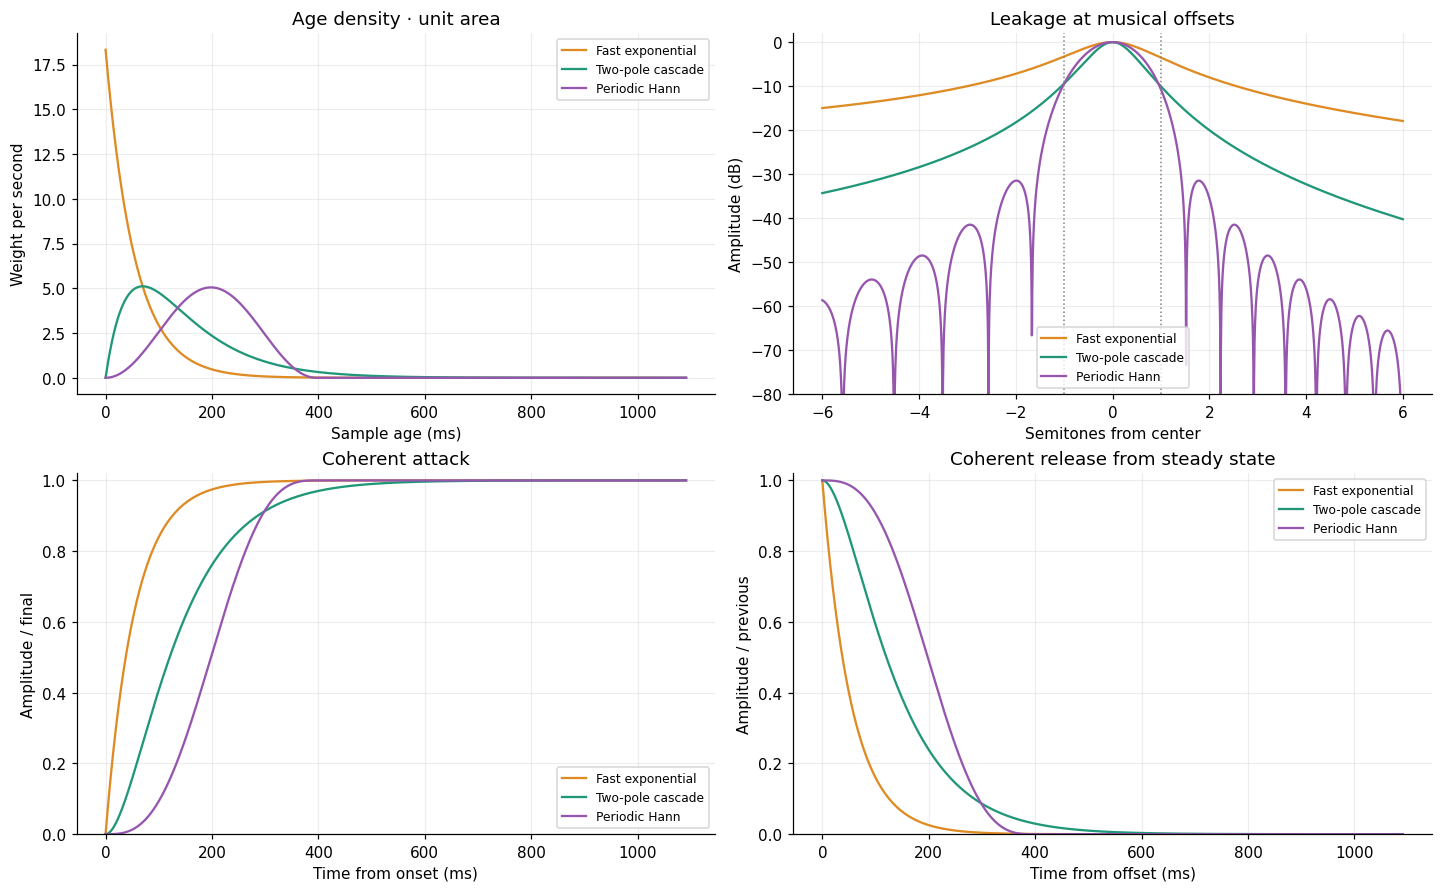

Leakage relative to the same filter's coherent center response:
offset (bins)      Fast dB     Cascade dB      Hann dB
     -2.0            -7.18         -18.24       -31.48
     -1.0            -3.26          -9.40        -9.40
     -0.5            -1.10          -3.65        -2.21
      0.5            -1.16          -3.82        -2.34
      1.0            -3.53         -10.06       -10.74
      2.0            -8.01         -20.00       -35.45
White-noise gains (unit coherent center gain; ENBW is two-sided):
Fast exponential         ENBW    9.167 Hz | RMS of 2*abs(z) / input noise RMS = 0.02764
Two-pole cascade         ENBW    3.438 Hz | RMS of 2*abs(z) / input noise RMS = 0.01693
Periodic Hann            ENBW    3.788 Hz | RMS of 2*abs(z) / input noise RMS = 0.01777
These noise RMS gains concern the second moment, not the mean noise magnitude.
A tone 20 dB louder contributes its leakage dB + 20 dB relative to a unit center tone.
Release to 10% equals attack to 90% here; these are not

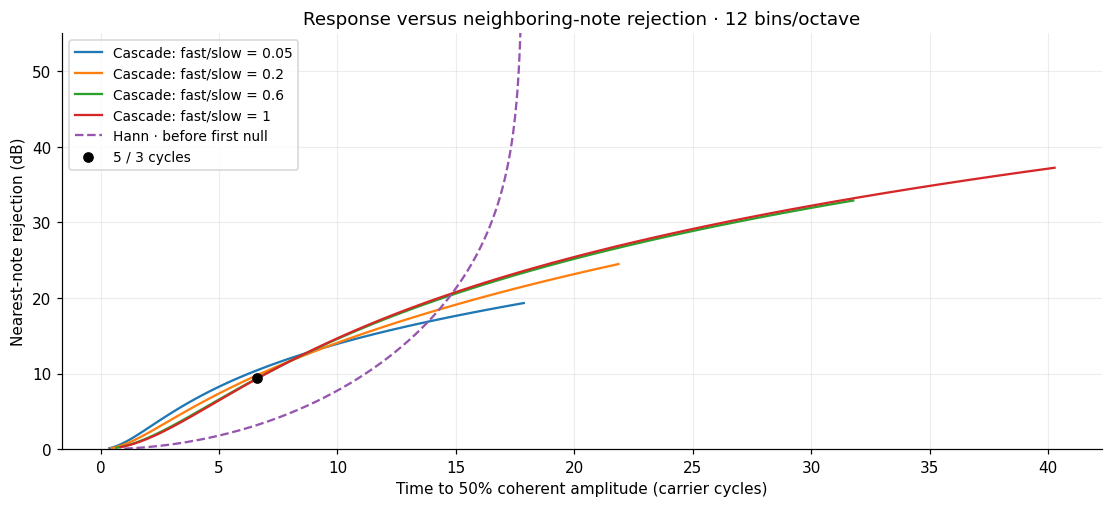

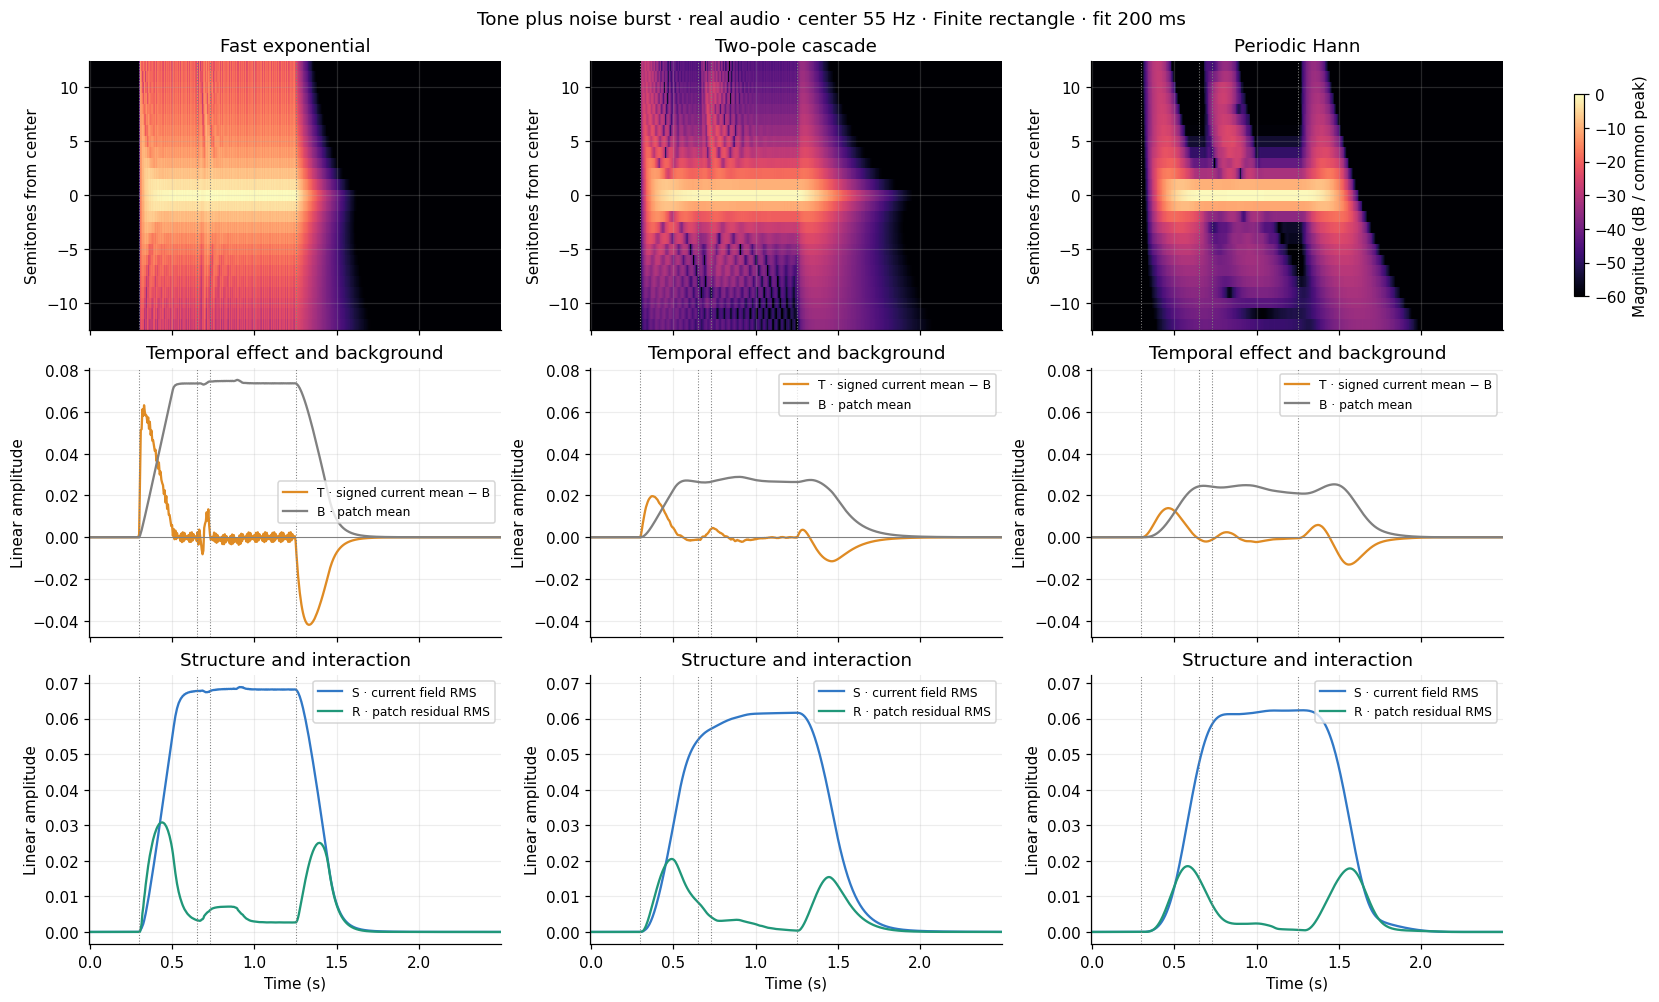

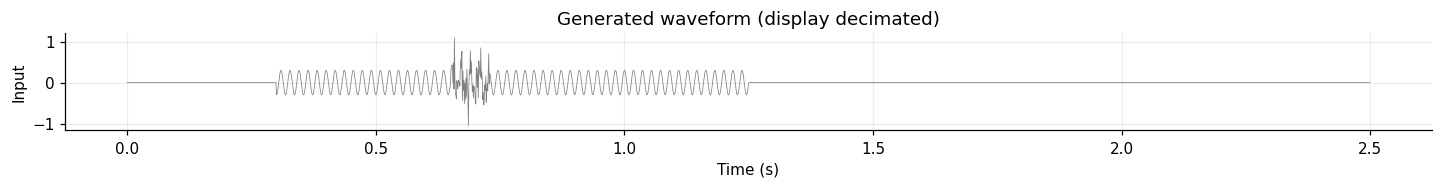

All paths share the input, fit settings, plot limits and coherent gain. Noise gains differ.
Frequency-dependent decay also changes how synchronized events line up across bins.
A rise in R can describe filter-induced spectral evolution; it does not by itself identify noise.
This is one centered patch, not the full collection of overlapping local production fits.


In [8]:
note_lab()
tradeoff_plot()
audio_experiment()

## Extension numerical checks

Check the new comparison rules, the weighted projection against independent least squares,
the FFT convolution against direct causal sums, and the finite-patch STBR identities.
These checks validate the analysis machinery, not a claim of optimal separation or a production replacement.

In [9]:
def verify_extension():
    fs, f0, slow, fast = 8000, 55., 5., 3.
    ts, tf = slow/f0, fast/f0
    n = choose_hann(fs, f0, ts, tf, 12, "Matched neighboring note", 17)
    gap = f0*(1-2**(-1/12))
    target = abs(responses(gap, fs, ts, tf)[2])
    error = abs(abs(hann_response(gap, fs, n))-target)
    assert all(error <= abs(abs(hann_response(gap, fs, j))-target)+1e-14 for j in [n-1, n+1])
    assert choose_hann(fs, f0, ts, tf, 12, "Production length", 17) == round(17*fs/f0)
    rng = np.random.default_rng(81)
    a = rng.uniform(0, 1, (9, 7))
    for slope_t in [False, True]:
        for slope_f in [False, True]:
            for weights in [np.ones(9), .8**np.arange(8, -1, -1)]:
                fit = project_patch(a, slope_t, slope_f, weights)
                # Independent full design: time profiles per bin and frequency profiles per row.
                t, x = np.meshgrid(np.arange(9), np.linspace(-1, 1, 7), indexing="ij")
                design = [np.ones(a.size)]
                for j in range(7):
                    column = np.broadcast_to(np.arange(7) == j, a.shape)
                    design.append(column.ravel())
                    if slope_t: design.append((column*t).ravel())
                for j in range(9):
                    row = np.broadcast_to((np.arange(9) == j)[:, None], a.shape)
                    design.append(row.ravel())
                    if slope_f: design.append((row*x).ravel())
                design = np.array(design).T
                root = np.sqrt(np.repeat(weights/weights.sum(), 7))
                beta = np.linalg.lstsq(design*root[:, None], a.ravel()*root, rcond=None)[0]
                np.testing.assert_allclose(fit["prediction"], (design@beta).reshape(a.shape), atol=2e-13)
                direct_rms = np.sqrt(np.sum(weights[:, None]*fit["residual"]**2)/(weights.sum()*7))
                np.testing.assert_allclose(fit["R"], direct_rms, atol=1e-14)
    flat = project_patch(a, False, False)
    np.testing.assert_allclose(flat["R"]**2,
                               np.var(a, axis=0).mean()-np.var(a.mean(axis=1)), atol=1e-14)
    for nt, nf in [(1, 7), (9, 1), (2, 7), (9, 2)]:
        z = rng.random((nt, nf))
        np.testing.assert_allclose(project_patch(z, True, True)["R"], 0, atol=2e-13)
    # Infinite-window noise gain, including the equal-pole limit.
    for s, f in [(5., 3.), (3., 3.), (3., 5.)]:
        a0, b0, ca0, cb0 = poles(fs, s/f0, f/f0)
        norm = ca0*cb0*(1+a0*b0)/((1+a0)*(1+b0)*(-np.expm1(-f0/(fs*s)-f0/(fs*f))))
        w = windows(np.arange(int(20*max(s, f)*fs/f0)), fs, s/f0, f/f0)[-1]
        np.testing.assert_allclose(np.sum(w*w), norm, rtol=2e-12)
    # Equal-mean-age EMA and rectangle also have equal white-observation effective counts.
    length = 41
    r = (length-1)/(length+1)
    np.testing.assert_allclose(r/(1-r), (length-1)/2)
    np.testing.assert_allclose((1+r)/(1-r), length)
    # Real input, FFT implementation, several actual frame times and all three filters.
    audio = rng.normal(size=400)
    times, bank = fft_filter_bank(audio, [55.], fs, slow, fast, "Production length")
    n = choose_hann(fs, f0, ts, tf, 12, "Production length", 17)
    kernels = filter_kernels(fs, f0, slow, fast, n, len(audio))
    carrier = np.exp(2j*np.pi*f0*np.arange(len(audio))/fs)
    for p, w in enumerate(kernels):
        direct = np.convolve(audio, w*carrier)[:len(audio)]
        np.testing.assert_allclose(bank[p][:, 0], 2*np.abs(direct[(times*fs).round().astype(int)]), atol=2e-14)
    # A flat time-frequency field has B only, including weighted startup.
    for mode in ["Finite rectangle", "Exponential (equal mean age)"]:
        trace = stbr_trace(np.ones((80, 7)), 200, weighting=mode)
        np.testing.assert_allclose(trace["B"], 1, atol=1e-14)
        for key in ["S", "T", "R"]: np.testing.assert_allclose(trace[key], 0, atol=1e-13)
    print("Passed: neighboring-note match, production length, weighted projection vs least squares,")
    print("flat ANOVA residual, degenerate supports, noise gains, EMA age/count, causal FFT convolution, and weighted startup.")

verify_extension()

Passed: neighboring-note match, production length, weighted projection vs least squares,
flat ANOVA residual, degenerate supports, noise gains, EMA age/count, causal FFT convolution, and weighted startup.
